<a href="https://colab.research.google.com/github/kunalbobade409-tech/Datheon_Machine_Learning_Data_Science_Internship/blob/main/Real_Estate_Housing_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset loaded successfully!
Dataset shape: (20640, 9)
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Training models...
Best Ridge alpha: {'model__alpha': 1}
Best Lasso alpha: {'model__alpha': 0.01}

MODEL COMPARISON
Model     RMSE      

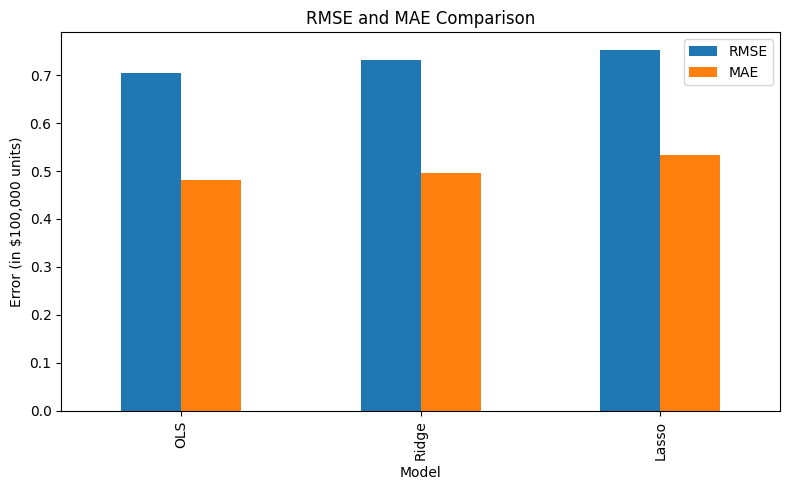

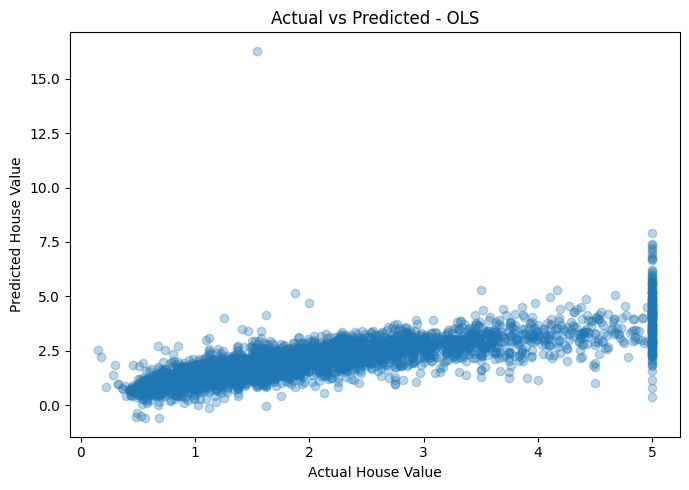

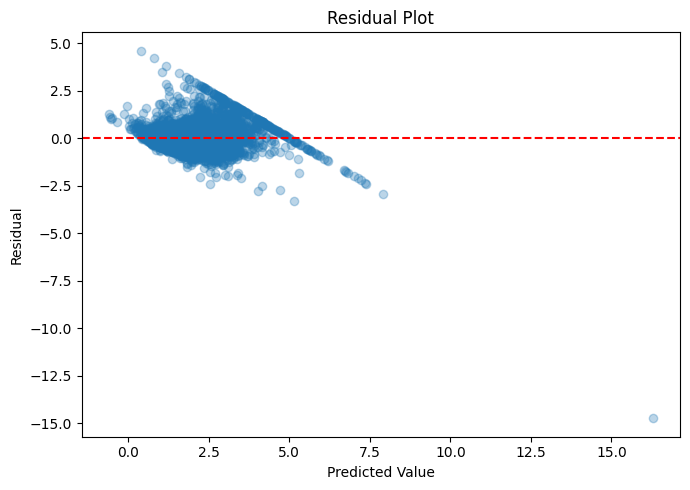

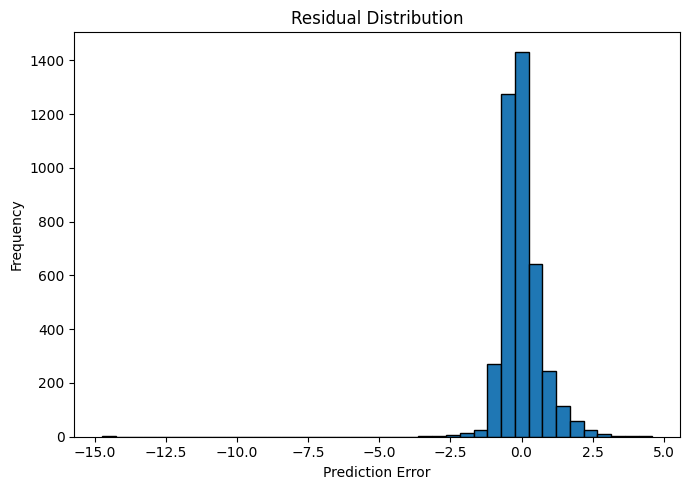


Best model: OLS
Model and results saved successfully!

Predicted median value: $68,841
Actual median value:    $47,700


In [1]:

# REAL ESTATE HOUSING PRICE PREDICTION
# OLS, Ridge & Lasso Regression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Load Dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

# 2. Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Separate Features and Target
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

# 4. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Preprocessing and Feature Engineering
preprocessing = [
    ("imputer", SimpleImputer(strategy="median")),
    ("features", PolynomialFeatures(
        degree=2, interaction_only=True, include_bias=False
    )),
    ("scaler", StandardScaler())
]

# 6. OLS Model
ols = Pipeline(preprocessing + [
    ("model", LinearRegression())
])

# 7. Ridge Model + Hyperparameter Tuning
ridge = GridSearchCV(
    Pipeline(preprocessing + [("model", Ridge())]),
    {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# 8. Lasso Model + Hyperparameter Tuning
lasso = GridSearchCV(
    Pipeline(preprocessing + [
        ("model", Lasso(max_iter=20000))
    ]),
    {"model__alpha": [0.001, 0.01, 0.1, 1, 10]},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# 9. Train Models
print("\nTraining models...")

ols.fit(X_train, y_train)
ridge.fit(X_train, y_train)
lasso.fit(X_train, y_train)

models = {
    "OLS": ols,
    "Ridge": ridge.best_estimator_,
    "Lasso": lasso.best_estimator_
}

print("Best Ridge alpha:", ridge.best_params_)
print("Best Lasso alpha:", lasso.best_params_)

# 10. Evaluate Models
results = []
predictions = {}

for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred

    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
        "R2 Score": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")

print("\nMODEL COMPARISON")
print(results_df.to_string(index=False))

# 11. Plot Model Comparison
results_df.plot(
    x="Model", y=["RMSE", "MAE"],
    kind="bar", figsize=(8, 5)
)
plt.title("RMSE and MAE Comparison")
plt.ylabel("Error (in $100,000 units)")
plt.tight_layout()
plt.show()

# 12. Actual vs Predicted
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]
best_pred = predictions[best_name]

plt.figure(figsize=(7, 5))
plt.scatter(y_test, best_pred, alpha=0.3)
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title(f"Actual vs Predicted - {best_name}")
plt.tight_layout()
plt.show()

# 13. Residual Analysis
residuals = y_test.to_numpy() - best_pred

plt.figure(figsize=(7, 5))
plt.scatter(best_pred, residuals, alpha=0.3)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Value")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.hist(residuals, bins=40, edgecolor="black")
plt.title("Residual Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 14. Save Best Model
joblib.dump(best_model, "housing_price_model.pkl")
results_df.to_csv("model_comparison.csv", index=False)

print("\nBest model:", best_name)
print("Model and results saved successfully!")

# 15. Sample Prediction
sample = X_test.iloc[[0]]
predicted_value = best_model.predict(sample)[0]
actual_value = y_test.iloc[0]

print(f"\nPredicted median value: ${predicted_value * 100000:,.0f}")
print(f"Actual median value:    ${actual_value * 100000:,.0f}")